In [130]:
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [131]:
torch.manual_seed(42)

In [132]:
df = pd.read_csv("08-seismic_activity_svm.csv")

In [133]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [135]:
df.describe()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
count,400.000000,4.000000e+02,400.000000
mean,0.000000,8.881784e-18,0.500000
std,7.719350,1.751650e+00,0.500626
min,-9.999954,-3.000000e+00,0.000000
25%,-6.134779,-1.500000e+00,0.000000
50%,0.000000,0.000000e+00,0.500000
75%,6.134779,1.500000e+00,1.000000
max,9.999954,3.000000e+00,1.000000


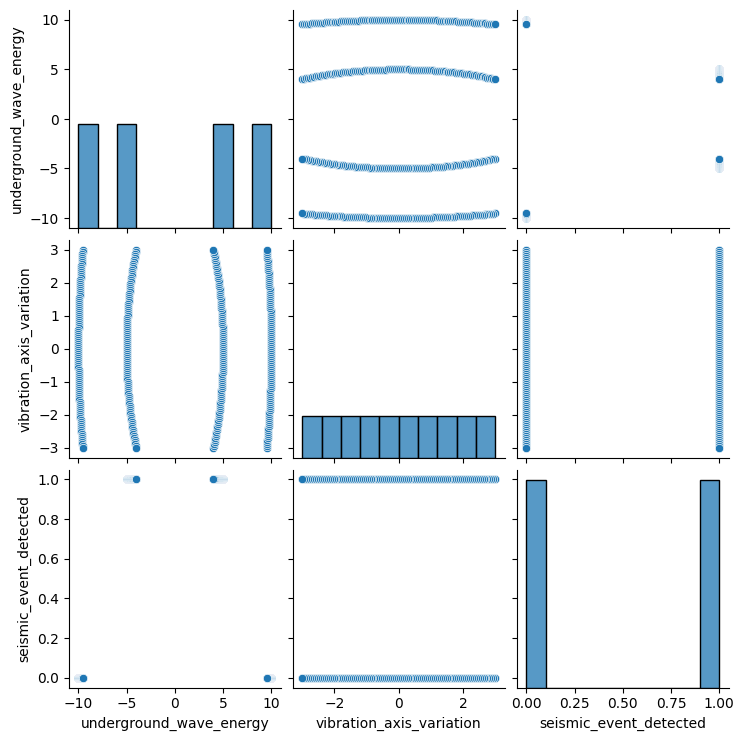

In [136]:
sns.pairplot(df)
plt.show()

In [137]:
from scipy.stats import skew

In [138]:
df.apply(skew, axis=0)

,0
underground_wave_energy,0.000000e+00
vibration_axis_variation,-1.327025e-17
seismic_event_detected,0.000000e+00


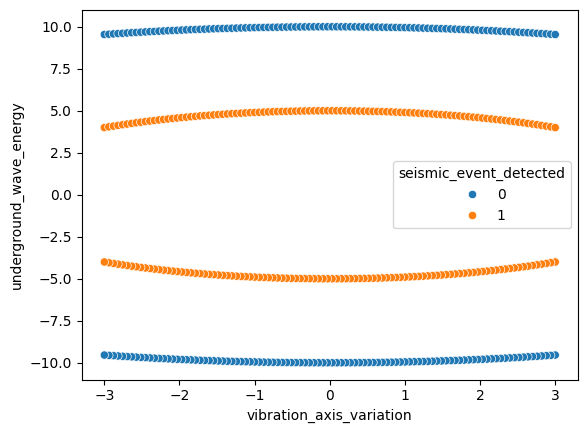

In [139]:
sns.scatterplot(data=df, x="vibration_axis_variation", y="underground_wave_energy", hue="seismic_event_detected")
plt.show()

In [140]:
from sklearn.model_selection import train_test_split

X = df.drop("seismic_event_detected", axis=1).values
y = df["seismic_event_detected"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [141]:
def calculate_accuracy(y_test, y_pred):
  correct = torch.eq(y_test, y_pred).sum().item()
  accuracy = (correct/len(y_test)) * 100
  return accuracy

In [142]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

In [143]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

(torch.Size([320, 2]),
 torch.Size([80, 2]),
 torch.Size([320, 1]),
 torch.Size([80, 1]))

In [144]:
from torch import nn

In [145]:
class LinearModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2, out_features=2)
    self.layer_2 = nn.Linear(in_features=2, out_features=1)

  def forward(self, x: torch.tensor) -> torch.tensor:
    return self.layer_2(self.layer_1(x))


In [146]:
model = LinearModel()

In [147]:
list(model.parameters())

[Parameter containing:
 tensor([[ 0.5406,  0.5869],
         [-0.1657,  0.6496]], requires_grad=True),
 Parameter containing:
 tensor([-0.1549,  0.1427], requires_grad=True),
 Parameter containing:
 tensor([[-0.3443,  0.4153]], requires_grad=True),
 Parameter containing:
 tensor([0.6233], requires_grad=True)]

In [148]:
model.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496]])),
             ('layer_1.bias', tensor([-0.1549,  0.1427])),
             ('layer_2.weight', tensor([[-0.3443,  0.4153]])),
             ('layer_2.bias', tensor([0.6233]))])

In [149]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.01)


In [150]:
epochs = 250

for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  y_pred = torch.sigmoid(y_logits)
  loss = loss_fn(y_pred, y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


  model.eval()
  with torch.inference_mode():
    test_pred_logits = model(X_test)
    test_pred = torch.sigmoid(test_pred_logits)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 5 == 0:
    print(f"epoch: {epoch} | train loss: {loss} | test loss: {test_loss}")


epoch: 0 | train loss: 1.1538172960281372 | test loss: 1.0101193189620972
epoch: 5 | train loss: 0.9807661771774292 | test loss: 0.8947064280509949
epoch: 10 | train loss: 0.883787989616394 | test loss: 0.8383170962333679
epoch: 15 | train loss: 0.8281283378601074 | test loss: 0.8117712140083313
epoch: 20 | train loss: 0.7950522303581238 | test loss: 0.8000496625900269
epoch: 25 | train loss: 0.7746867537498474 | test loss: 0.7956267595291138
epoch: 30 | train loss: 0.761709988117218 | test loss: 0.7946873903274536
epoch: 35 | train loss: 0.7531485557556152 | test loss: 0.7952672243118286
epoch: 40 | train loss: 0.7472849488258362 | test loss: 0.7963536977767944
epoch: 45 | train loss: 0.743099570274353 | test loss: 0.7974379658699036
epoch: 50 | train loss: 0.7399749755859375 | test loss: 0.7982820868492126
epoch: 55 | train loss: 0.7375310063362122 | test loss: 0.7987940311431885
epoch: 60 | train loss: 0.7355313897132874 | test loss: 0.7989582419395447
epoch: 65 | train loss: 0.7338

In [151]:
y_pred_linear = torch.round(test_pred)
y_pred_linear = y_pred_linear.squeeze(1)

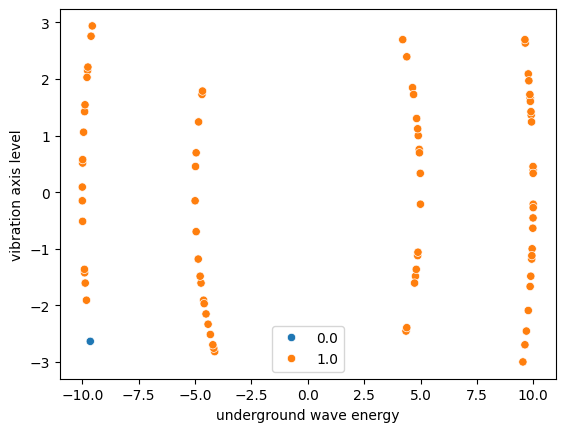

In [152]:
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_pred_linear)
plt.xlabel("underground wave energy")
plt.ylabel("vibration axis level")
plt.legend()
plt.show()

In [153]:
y_pred_linear_acc_score = calculate_accuracy(y_test=y_test, y_pred=torch.round(test_pred))

In [154]:
from torch.nn import ReLU

In [155]:
relu = ReLU()

In [156]:
relu(torch.randn(1,2,3))

tensor([[[1.5231, 0.6647, 0.0000],
         [0.0000, 0.0000, 0.0000]]])

In [157]:
import torch.nn.functional as F

In [158]:
class NonLinearModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer1 = nn.Linear(in_features=2, out_features=5)
    self.layer2 = nn.Linear(in_features=5, out_features=5)
    self.layer3 = nn.Linear(in_features=5, out_features=1)
    self.relu = nn.ReLU()

  def forward(self, x: torch.tensor) -> torch.tensor:
    x = self.layer1(x)
    x = self.relu(x)
    x = self.layer2(x)
    x = self.relu(x)
    x = self.layer3(x)

    return x


In [159]:
model = NonLinearModel()

In [160]:
model.parameters()

<generator object Module.parameters at 0x7f6ffaedcd60>

In [161]:
model.state_dict()

OrderedDict([('layer1.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]])),
             ('layer1.bias',
              tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370])),
             ('layer2.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202],
                      [-0.1213,  0.1882,  0.3993,  0.2585, -0.1955],
                      [ 0.2582,  0.0800,  0.2271, -0.2726, -0.4427],
                      [-0.1728, -0.3430,  0.3670,  0.1288,  0.1852],
                      [ 0.1414, -0.0078,  0.3500, -0.3178,  0.0282]])),
             ('layer2.bias',
              tensor([-0.3052,  0.1379, -0.1540,  0.1370, -0.0932])),
             ('layer3.weight',
              tensor([[ 0.3709, -0.2651, -0.2667, -0.2667,  0.4022]])),
             ('layer3.bias', tensor([0.1490]))])

In [162]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)

In [163]:
epochs = 300

for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  loss = loss_fn(torch.sigmoid(y_logits), y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model.eval()
  with torch.inference_mode():
    test_logits = model(X_test)
    test_pred = torch.sigmoid(test_logits)
    test_loss = loss_fn(test_pred, y_test)


  if epoch % 5 == 0:
    print(f"epoch: {epoch} | train loss: {loss} | test loss: {test_loss}")

epoch: 0 | train loss: 0.680698037147522 | test loss: 0.6919938325881958
epoch: 5 | train loss: 0.6479726433753967 | test loss: 0.6511113047599792
epoch: 10 | train loss: 0.6307047009468079 | test loss: 0.6273536682128906
epoch: 15 | train loss: 0.616754412651062 | test loss: 0.6088005304336548
epoch: 20 | train loss: 0.6041362285614014 | test loss: 0.5930690765380859
epoch: 25 | train loss: 0.5921498537063599 | test loss: 0.5792149901390076
epoch: 30 | train loss: 0.5804056525230408 | test loss: 0.566483736038208
epoch: 35 | train loss: 0.5686982274055481 | test loss: 0.5544701218605042
epoch: 40 | train loss: 0.5569579601287842 | test loss: 0.5429096221923828
epoch: 45 | train loss: 0.5451783537864685 | test loss: 0.5314284563064575
epoch: 50 | train loss: 0.5333095788955688 | test loss: 0.5199133157730103
epoch: 55 | train loss: 0.5212587118148804 | test loss: 0.5084678530693054
epoch: 60 | train loss: 0.5085597038269043 | test loss: 0.49635037779808044
epoch: 65 | train loss: 0.495

In [164]:
test_pred

tensor([[0.9317],
        [0.9217],
        [0.0406],
        [0.9291],
        [0.0729],
        [0.0605],
        [0.9563],
        [0.0745],
        [0.8916],
        [0.0188],
        [0.0600],
        [0.9416],
        [0.0407],
        [0.0493],
        [0.0171],
        [0.0370],
        [0.9171],
        [0.9550],
        [0.8757],
        [0.9709],
        [0.0534],
        [0.0534],
        [0.9796],
        [0.9017],
        [0.0733],
        [0.9855],
        [0.0238],
        [0.8899],
        [0.8844],
        [0.0307],
        [0.9844],
        [0.0253],
        [0.8827],
        [0.0411],
        [0.8735],
        [0.0227],
        [0.0243],
        [0.9444],
        [0.0143],
        [0.0155],
        [0.9642],
        [0.0403],
        [0.0525],
        [0.0452],
        [0.0582],
        [0.9659],
        [0.0147],
        [0.0167],
        [0.0473],
        [0.0150],
        [0.0378],
        [0.9656],
        [0.9474],
        [0.0479],
        [0.9511],
        [0

In [165]:
y_pred_relu_acc_score = calculate_accuracy(y_test=y_test, y_pred=torch.round(test_pred))

In [166]:
y_pred_relu = torch.round(test_pred)

In [167]:
y_pred_relu = y_pred_relu.squeeze(1)

In [168]:
type(y_pred_relu)

torch.Tensor

In [169]:
type(X_test)

torch.Tensor

In [170]:
X_test.shape

torch.Size([80, 2])

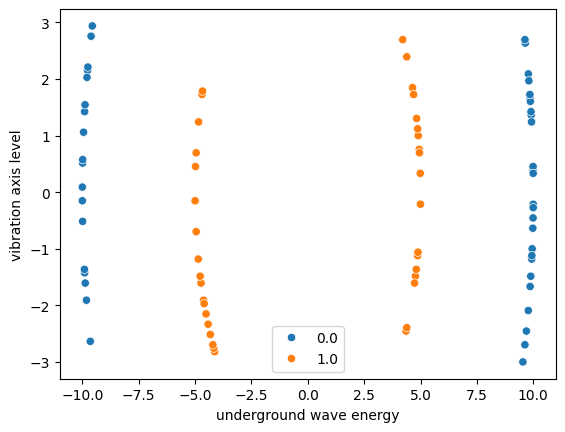

In [171]:
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_pred_relu)
plt.xlabel("underground wave energy")
plt.ylabel("vibration axis level")
plt.legend()
plt.show()

In [172]:
#report

print(f"Model Accuracy Score without ReLU: {y_pred_linear_acc_score}\n")
print(f"Model Accuracy Score with ReLU: {y_pred_relu_acc_score}")


Model Accuracy Score without ReLU: 46.25

Model Accuracy Score with ReLU: 100.0


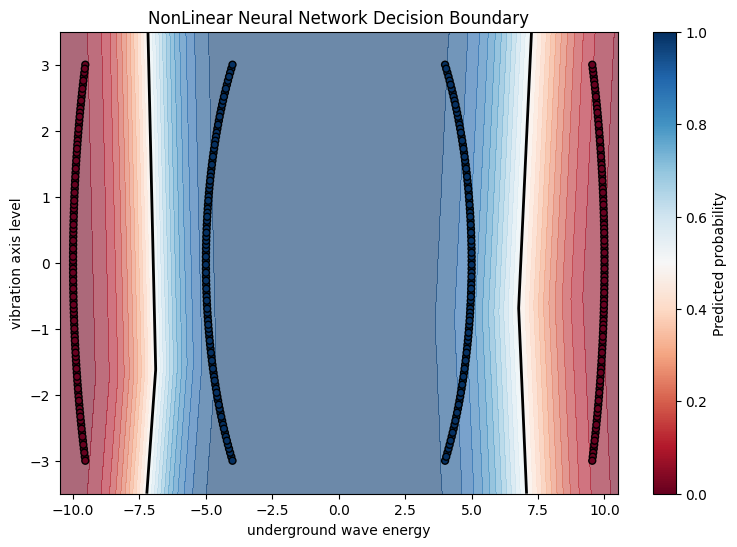

In [175]:
# decision boundry plot


import numpy as np
import matplotlib.pyplot as plt

# Train ve test verilerini birleştiriyoruz
X = torch.cat([X_train, X_test], dim=0)
y = torch.cat([y_train, y_test], dim=0)

# İki özellik için koordinat aralıkları
x_min, x_max = X[:, 0].min().item() - 0.5, X[:, 0].max().item() + 0.5
y_min, y_max = X[:, 1].min().item() - 0.5, X[:, 1].max().item() + 0.5

# İki boyutlu grid oluşturuyoruz
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Grid noktalarını modele uygun hale getiriyoruz
grid = np.c_[xx.ravel(), yy.ravel()]
grid_tensor = torch.tensor(
    grid,
    dtype=X_train.dtype,
    device=X_train.device
)

# Modelin tahminleri
model.eval()

with torch.inference_mode():
    logits = model(grid_tensor)
    probabilities = torch.sigmoid(logits)
    Z = probabilities.reshape(xx.shape).cpu().numpy()

# Görselleştirme
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, levels=30, cmap="RdBu", alpha=0.6)

# Karar sınırı: P(y=1|x) = 0.5
plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=2)

plt.scatter(
    X[:, 0].cpu().numpy(),
    X[:, 1].cpu().numpy(),
    c=y.reshape(-1).cpu().numpy(),
    cmap="RdBu",
    edgecolors="black",
    s=25
)

plt.colorbar(label="Predicted probability")
plt.xlabel("underground wave energy")
plt.ylabel("vibration axis level")
plt.title("NonLinear Neural Network Decision Boundary")
plt.show()
